In [1]:
# standard libraries
import os, sys, json, time, glob
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from skimage.metrics import peak_signal_noise_ratio as psnr
from datetime import datetime
import copy
import inspect

sys.path.append(os.getcwd())
from model.model import build_unet, UNetVelocity
from loss.loss import ambient_flow_loss, flow_loss
from data.data import BrainAmbientFlowMatchingDataset
from util.helper import *

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [2]:
N_COILS = 16
DELTA, EPS, LR = 0.1, 1e-3, 1e-4
BATCH_SIZE = 4
MAX_STEPS, val_every = 100, 20
save_path = "/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/run"; os.makedirs(save_path, exist_ok=True)
ckpt_dir = "/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/ckpt_ambient_fm"; os.makedirs(ckpt_dir, exist_ok=True)

In [3]:
split_index = json.load(open("/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/split_16x320x320.json"))
run_dir = os.path.join(save_path, datetime.now().strftime("%Y%m%d_%H%M%S"))
os.makedirs(run_dir, exist_ok=True)

train_set = BrainAmbientFlowMatchingDataset(index=split_index["train"], accel=4, cf=0.08)
val_set   = BrainAmbientFlowMatchingDataset(index=split_index["val"],   accel=4, cf=0.08)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                                           num_workers=4, pin_memory=True, drop_last=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)


In [4]:
model = build_unet(n_coils=N_COILS, with_mask=False).to(device)
optim = torch.optim.AdamW(model.parameters(), lr=LR)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")
print(type(model))                              # e.g. <class 'diffusers...UNet2DModel'>
print(inspect.getsourcefile(type(model)))       # path to the .py file
print(inspect.signature(model.forward))         # its arguments

25.3M parameters
<class 'diffusers.models.unets.unet_2d.UNet2DModel'>
/egr/research-slim/luozishe/miniconda3/envs/flow_matching/lib/python3.9/site-packages/diffusers/models/unets/unet_2d.py
(sample: torch.Tensor, timestep: Union[torch.Tensor, float, int], class_labels: Optional[torch.Tensor] = None, return_dict: bool = True) -> Union[diffusers.models.unets.unet_2d.UNet2DOutput, Tuple]


torch.Size([1, 16, 320, 320]) torch.Size([1, 1, 1, 320])


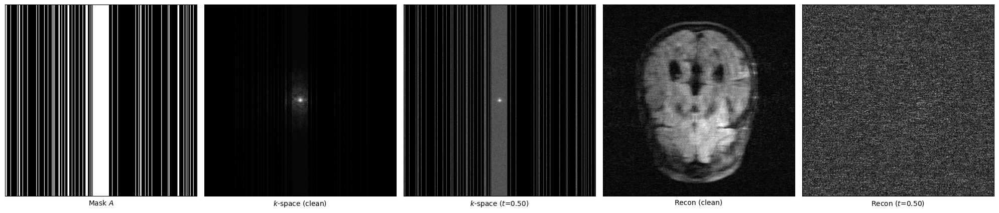

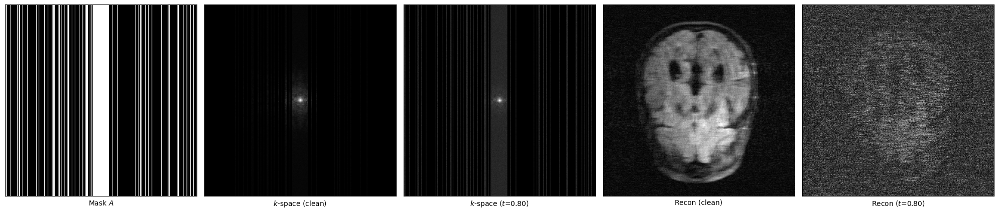

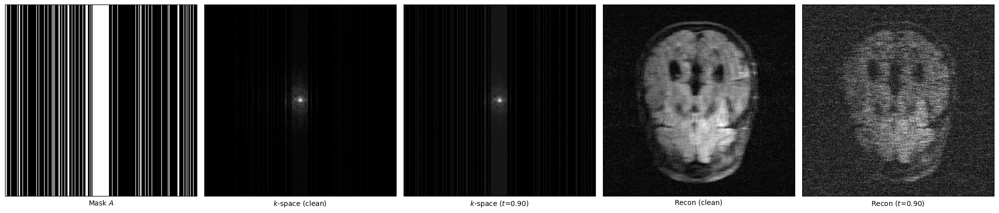

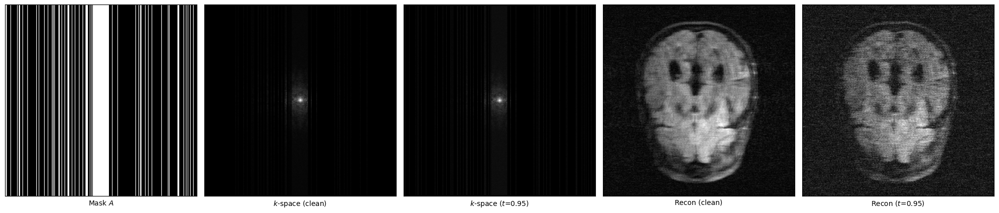

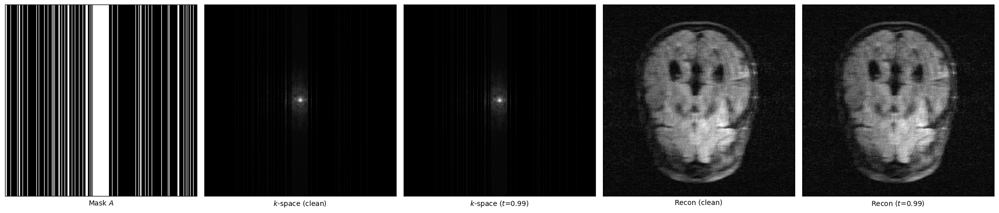

In [5]:
fix_Ay, fix_A, _ = val_set[80]                 # one slice: (16, 320, 320), (1, 1, 320)
fix_Ay, fix_A = fix_Ay[None], fix_A[None]      # (1, 16, 320, 320), (1, 1, 1, 320)
print(fix_Ay.shape, fix_A.shape)
# plot_recon(model, fix_y, fix_A, t0=EPS)
for t0 in [0.5, 0.8, 0.9, 0.95, 0.99]:
    plot_image(fix_Ay, fix_A, t=t0)

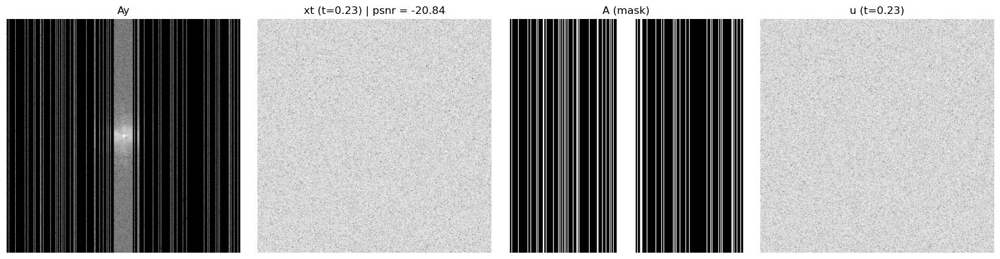

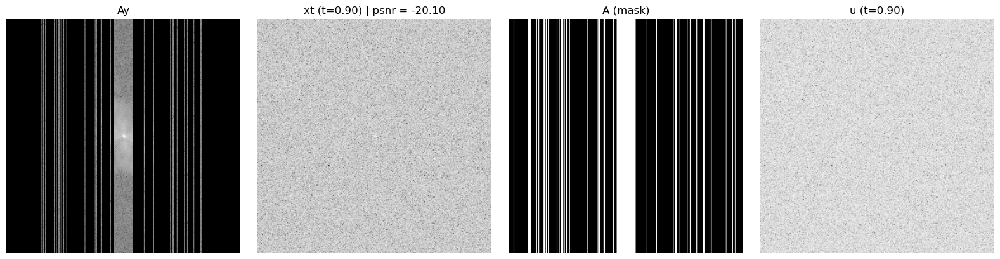

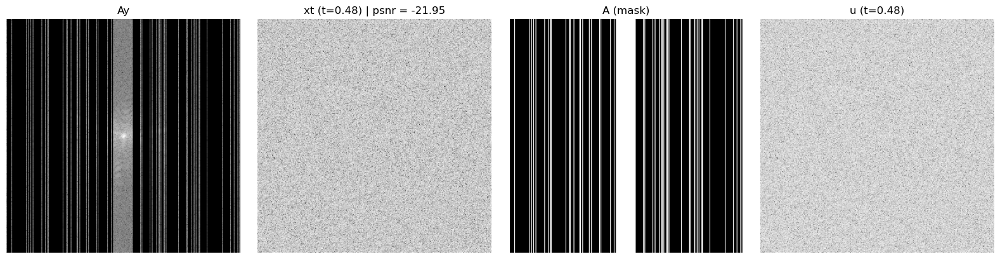

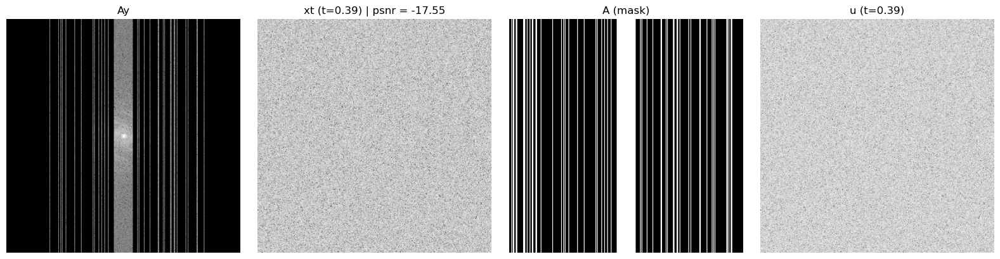

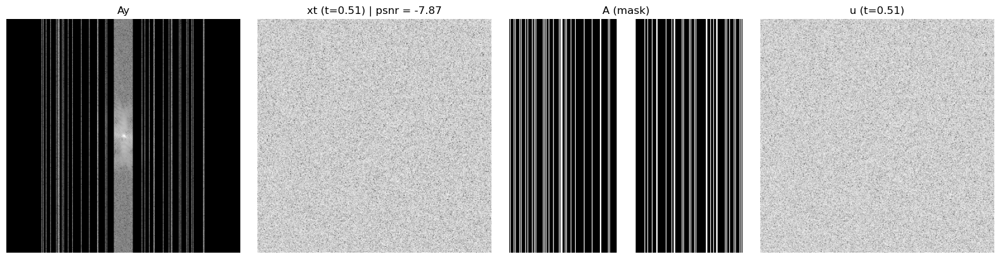

...

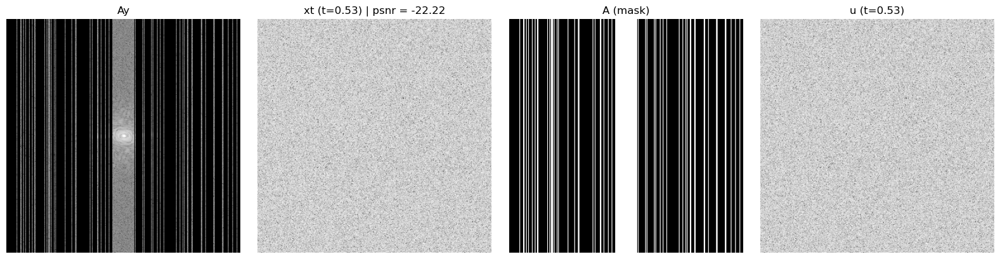

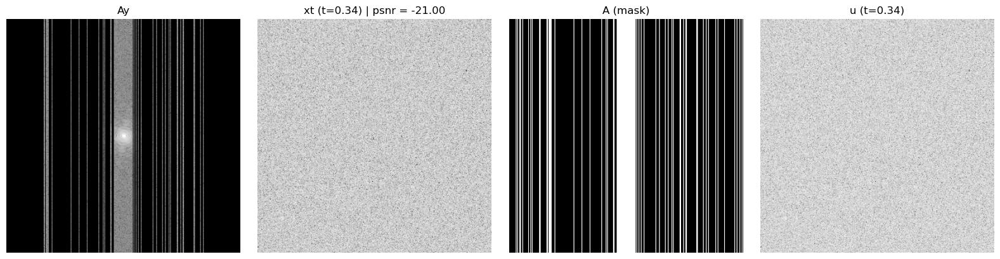

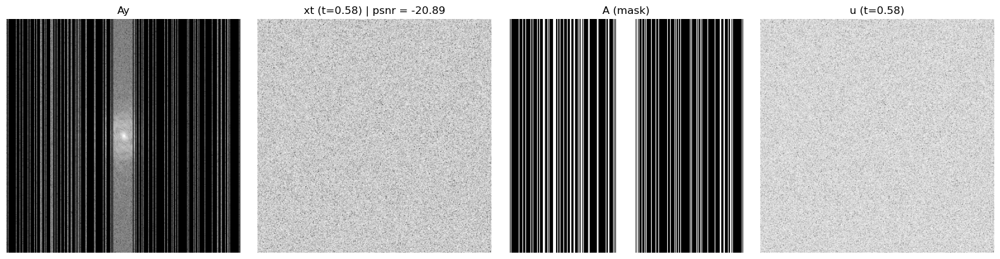

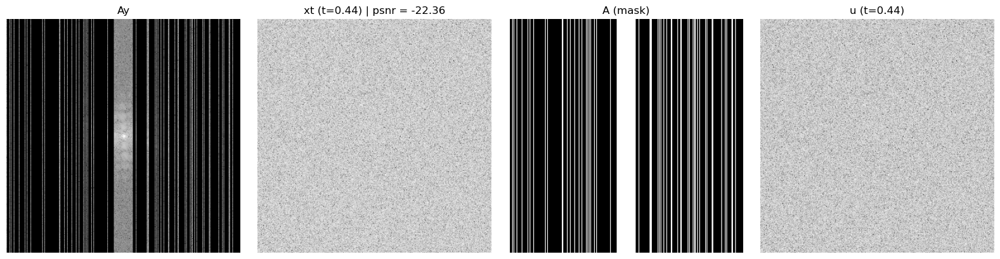

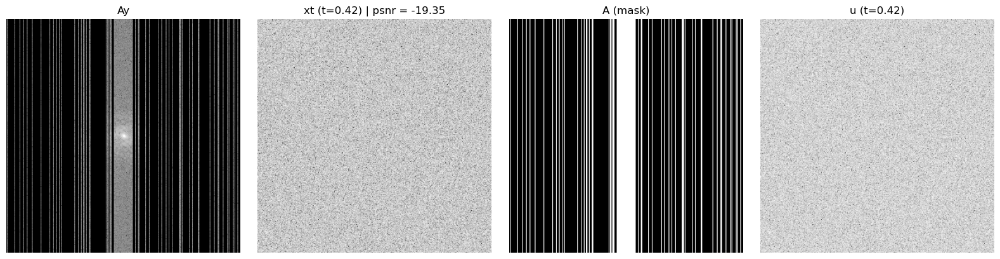

In [ ]:
train_losses, val_losses, train_steps, val_steps = [], [], [], []
start_time = time.time()
best_val, best_state, best_step = float("inf"), None, 0

for epoch in range(1, MAX_STEPS + 1):
    # ---- train ----
    model.train()
    epoch_losses = []
    it = 0
    for Ay, A, _ in train_loader:
        it += 1
        Ay, A = Ay.to(device), A.to(device)
        train_loss = 0
        t = torch.rand(Ay.shape[0], device=device).view(-1, 1, 1, 1)
        if it % 20 == 0:
            train_loss = flow_loss(model, Ay, A, t, eps=EPS, plot=True, gen=None)[0]
        else:
            train_loss = flow_loss(model, Ay, A, t, eps=EPS, plot=False, gen=None)[0]
        optim.zero_grad(set_to_none=True)
        train_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optim.step()
        epoch_losses.append(train_loss.item())
    train_losses.append(np.mean(epoch_losses))               # mean over the epoch
    train_steps.append(epoch)
    print(f"epoch {epoch}: train {train_losses[-1]:.4f}")
    # ---- validate ----
    model.eval()
    torch.manual_seed(0)                                     # same randomness every epoch
    with torch.no_grad():
        val_loss = np.mean([flow_loss(model, vAy.to(device), vA.to(device),
                                    torch.rand(vAy.shape[0], device=device).view(-1, 1, 1, 1),
                                    eps=EPS, plot=False, gen=None)[0].item()
                            for vAy, vA, _ in val_loader])    # mean over all val batches
    val_losses.append(val_loss)
    val_steps.append(epoch)
    print(f"epoch {epoch}: train {train_losses[-1]:.4f}  val {val_loss:.4f}")

    # ---- checkpoint: once per epoch, on the mean val loss ----
    if val_loss < best_val:
        best_val, best_step = val_loss, epoch
        torch.save({"model": model.state_dict(), "best_val": best_val, "best_step": best_step},
                   f"{run_dir}/best.pt")

In [ ]:
run_dir = os.path.join(save_path, datetime.now().strftime("%Y%m%d_%H%M%S"))
os.makedirs(run_dir, exist_ok=True)

plt.figure(figsize=(6, 4))
plt.semilogy(train_steps, train_losses, alpha=0.4, label="train")
if val_losses: plt.semilogy(val_steps, val_losses, "o-", label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Loss"); plt.legend(); plt.tight_layout()
plt.savefig(f"{run_dir}/loss.png", dpi=150); plt.close()

# PSNR: train vs. validation
plt.figure(figsize=(6, 4))
if train_psnr: plt.plot(train_steps, train_psnr, alpha=0.6, label="train")
if val_psnr:   plt.plot(val_steps, val_psnr, "o-", label="val")
plt.xlabel("step"); plt.ylabel("PSNR (dB)"); plt.title("PSNR"); plt.legend(); plt.tight_layout()
plt.savefig(f"{run_dir}/psnr.png", dpi=150); plt.close()

print("saved:", os.listdir(run_dir))

torch.save({"model": best_state, "best_val": best_val, "best_step": best_step}, f"{run_dir}/best.pt")
print("best checkpoint saved:", f"{run_dir}/best.pt")
